In [1]:
import torch
import torch.nn.functional as  F
import matplotlib.pyplot as plt

In [2]:
# splitlines()方法将字符串按行分割，返回一个包含各行内容的列表，自动去除行尾的换行符
words=open('names.txt','r').read().splitlines()
words[:3]

['emma', 'olivia', 'ava']

In [3]:
len(words)

32033

In [4]:
chars=sorted(list(set(''.join(words))))
# 先给特殊字符'.'分配索引0
stoi={'.' : 0}
# 然后给其他字符分配索引1开始的编号
stoi.update({s:i+1 for i,s in enumerate(chars)})

# 方法1：直接从字符列表创建索引到字符的映射
#itos={i:s for i,s in enumerate(chars)}

# 方法2：从字符到索引的映射(stoi)反向创建索引到字符的映射
itos={i:s for s,i in stoi.items()}

# 区别说明：
# 方法1：直接使用enumerate(chars)，按chars列表的顺序创建映射
# 方法2：从已有的stoi字典反向创建，通过交换键值对的位置
# 两种方法结果相同，但方法2可以实现把['.']字符赋值0



调试开始后，会出现调试控制栏：

F10 - 单步跳过（执行当前行，不进入函数内部）

F11 - 单步进入（如果当前行有函数调用，进入函数内部）
Shift+F11 - 单步跳出（跳出当前函数）

F5 - 继续执行（运行到下一个断点）
Shift+F5 - 停止调试

In [5]:
# 设置上下文窗口大小为3，即使用前3个字符来预测下一个字符
block_size = 3
# 初始化输入特征列表X和目标标签列表Y
X,Y=[],[]
# 遍历每个单词
for w in words:
    # 初始化上下文为3个'.'字符（索引为0）
    context = [0]*block_size
    # 遍历单词中的每个字符，加上结束符'.'
    #print(context)
    for ch in w + '.':
        # 获取当前字符的索引
        #print(ch)
        ix=stoi[ch]
        #print(ix)

        # 将当前上下文作为输入特征添加到X
        X.append(context)
        # 将当前字符索引作为目标标签添加到Y
        Y.append(ix)
        # 打印当前上下文和预测目标，用于可视化数据构建过程
        #print(''.join(itos[i] for i in context), '--->', itos[ix])

        # 更新上下文：移除第一个字符，在末尾添加当前字符索引
        context = context[1:]+[ix]
        #print(context)

X=torch.tensor(X)
Y=torch.tensor(Y)


# 这段代码实现了一个滑动窗口的数据预处理逻辑：
# 固定窗口大小:block_size = 3 设置每次读取3个字符作为输入

# 输入-输出对:将每个3字符的context作为输入X,对应的下一个字符索引作为输出Y
# 滑动更新:context = context[1:]+[ix] 实现窗口滑动（去掉第一个，加上新的字符）

# 循环构建：对每个字符重复此过程，构建训练数据集
# 例如对于单词"emma":
# [0,0,0] → e
# [0,0,e] → m
# [0,e,m] → m
# [e,m,m] → a
# [m,m,a] → .
# 这样就为神经网络创建了"给定前3个字符，预测下1个字符"的监督学习数据


In [6]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [7]:
block_size = 3 # context length: how many characters do we take to predict the next one?

# 将数据构建逻辑封装成函数，方便后续划分训练集、验证集和测试集
def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

In [8]:
# 导入random模块用于数据集随机化
import random
# 设置随机种子确保结果可重现
random.seed(42)
# 随机打乱单词列表，避免数据顺序偏差
random.shuffle(words)

# 计算数据集划分的分界点
n1=int(0.8*len(words))  # 80%作为训练集
n2=int(0.9*len(words))  # 90%分界点，用于划分验证集和测试集

# 构建训练集：使用前80%的数据
Xtr, Ytr = build_dataset(words[:n1])
# 构建验证集：使用80%-90%的数据
Xdev, Ydev = build_dataset(words[n1:n2])
# 构建测试集：使用最后10%的数据
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [9]:
C = torch.randn((27, 2))

In [10]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [11]:
W1=torch.randn((6,100))
b1=torch.randn(100)


In [12]:
h=torch.tanh(emb.view(-1,6)@W1+b1)

In [13]:
h


tensor([[ 0.5444, -0.1870, -0.9518,  ...,  0.2757, -0.4728,  0.8078],
        [ 0.8828,  0.7961, -0.9983,  ...,  0.8454, -0.9375,  0.6295],
        [ 0.7426,  0.9029, -0.8629,  ..., -0.3878, -0.9994,  0.9999],
        ...,
        [ 0.9725, -0.9275, -0.9793,  ...,  0.9499, -0.9944,  0.7663],
        [-0.7993,  0.9968, -0.9402,  ...,  0.9923,  0.9712,  0.9952],
        [ 0.9371, -0.8830,  0.9553,  ..., -0.9968, -0.9965,  0.9999]])

In [14]:
h.shape

torch.Size([228146, 100])

In [15]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [16]:
logits = h @ W2 + b2
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)


In [17]:
# 这里的问题是索引不匹配
# torch.arange(32) 产生形状为 [32] 的张量
# 但是 Ytr 的形状是 [182625] (从上下文可以看出)
# 我们需要使用所有样本，而不只是前32个

# 正确的做法应该是：
loss = -prob[torch.arange(Ytr.shape[0]), Ytr].log().mean()
loss

tensor(18.9872)

In [18]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [59]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [60]:
# nelement() 是 PyTorch 张量的一个方法，用于返回张量中元素的总数量
# 它等价于 tensor.numel()，计算张量所有维度的乘积
# 例如：一个形状为 (3, 4, 5) 的张量有 3*4*5 = 60 个元素


# 计算所有参数的总数量
sum(p.nelement() for p  in  parameters)

11897

In [61]:
for p in parameters:
  p.requires_grad = True

In [62]:
# 创建学习率搜索的范围
# lre: 在对数空间中从-3到0均匀分布的1000个点 (即从10^-3到10^0的指数)
# lrs: 将对数空间的值转换为实际的学习率值 (从0.001到1.0)
# 用法：在训练循环中使用 lr = lrs[i] 来设置第i步的学习率
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [63]:
lri = []
lossi = []
stepi = []

In [64]:
for i in range(200000):
    ix = torch.randint(0,Xtr.shape[0],(32,))
    emb = C[Xtr[ix]] # (32, 3, 10)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
    logits = h @ W2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    
    # update
    #lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    #lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())

    #print(loss.item())

In [ ]:
# 学习率搜索方法
# 该方法通过在训练过程中逐步增加学习率，观察损失函数的变化来找到最优学习率
# 当学习率过小时，损失下降缓慢；当学习率过大时，损失会急剧上升
# 最优学习率通常在损失下降最快的区域

# lri = []
# lossi = []

# for i in range(1000):
#     # 构建小批次数据
#     ix = torch.randint(0, Xtr.shape[0], (32,))
    
#     # 前向传播
#     emb = C[Xtr[ix]]  # (32, 3, 10)
#     h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 200)
#     logits = h @ W2 + b2  # (32, 27)
#     loss = F.cross_entropy(logits, Ytr[ix])
    
#     # 反向传播
#     for p in parameters:
#         p.grad = None
#     loss.backward()
    
#     # 使用当前学习率更新参数
#     lr = lrs[i]
#     for p in parameters:
#         p.data += -lr * p.grad
    
#     # 记录学习率和损失值
#     lri.append(lre[i])
#     lossi.append(loss.log10().item())

# print(f"学习率搜索完成，测试了 {len(lri)} 个学习率值")


学习率搜索完成，测试了 1000 个学习率值


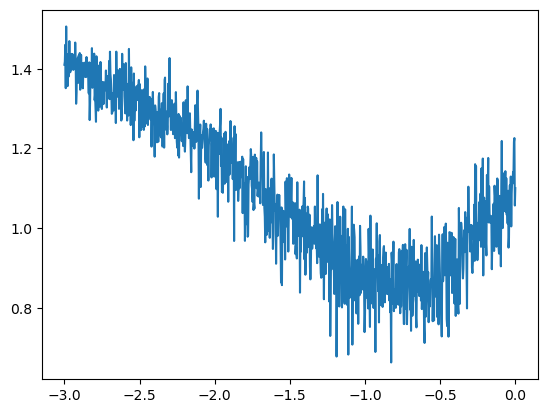

In [ ]:
# 绘制学习率与损失值的关系图
# 这个图可以帮助我们找到最优的学习率
# 通常最优学习率位于损失下降最陡峭的区域
#plt.plot(lri, lossi)

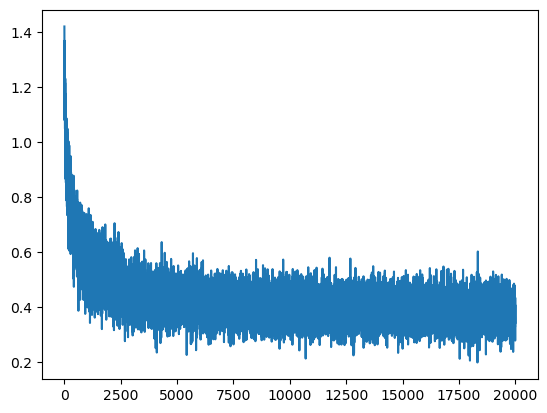

In [53]:
plt.plot(stepi, lossi)

In [65]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1268, grad_fn=<NllLossBackward0>)

In [66]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1671, grad_fn=<NllLossBackward0>)

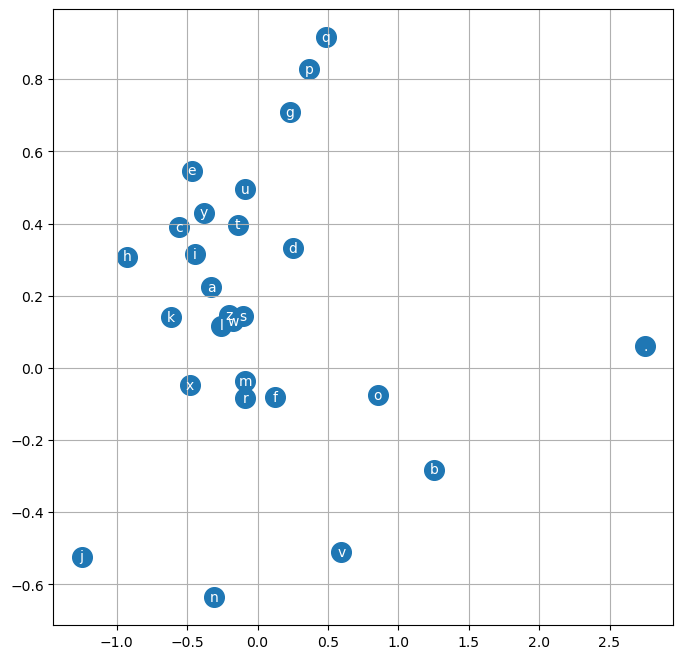

In [67]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [68]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [69]:
# 从训练好的模型中采样生成新的名字
g = torch.Generator().manual_seed(2147483647 + 10)  # 设置随机种子确保结果可复现

for _ in range(20):  # 生成20个名字
    
    out = []  # 存储生成的字符索引
    context = [0] * block_size  # 初始化上下文，全部填充为'.'字符的索引(0)
    while True:  # 持续生成字符直到遇到结束符
      emb = C[torch.tensor([context])]  # 获取上下文的嵌入向量 (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)  # 计算隐藏层输出
      logits = h @ W2 + b2  # 计算输出层logits
      probs = F.softmax(logits, dim=1)  # 将logits转换为概率分布
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()  # 根据概率分布采样下一个字符
      context = context[1:] + [ix]  # 更新上下文：移除第一个字符，添加新生成的字符
      out.append(ix)  # 将生成的字符添加到输出序列
      if ix == 0:  # 如果生成的是结束符'.'，则停止生成
        break
    
    print(''.join(itos[i] for i in out))  # 将字符索引转换为字符并打印生成的名字

mora.
kayah.
see.
mel.
ryah.
rethristadrie.
cailee.
selin.
shi.
jenre.
eliean.
nar.
kayzion.
karin.
shub.
ridhiriel.
kindreelynn.
novacy.
ura.
ted.
